# 07 · Fine-tuning I: SFT, LoRA and distillation

A pretrained LM continues text. Post-training turns it into something that follows instructions.

| stage | data | objective | what changes |
|---|---|---|---|
| **SFT** | (instruction → response) pairs | next-token on the *response only* | format + instruction following |
| preferences (DPO) | (prompt, chosen, rejected) | maximize preference | tone, helpfulness, safety (→ notebook 08) |
| RL with verifiable rewards (GRPO) | problems with checkable answers | reward | reasoning (→ notebook 08) |

**This notebook:** SFT with loss masking → LoRA (train 1–2 % of parameters, merge for free inference) → distillation into a smaller student → evaluation of each on the same held-out set.

**Source:** `llmsuite/finetune.py`, `llmsuite/data.py` (`ChatFormat`).

In [1]:
import os, sys, math, time, random, copy
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llmsuite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # climb from notebooks/<topic>/ up to the repo root
sys.path.insert(0, ROOT)                            # so that `import llmsuite` works from any notebook
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from llmsuite.utils import seed_everything, get_device, count_params, human
seed_everything(0)
device = get_device()
print("torch", torch.__version__, "| device", device)

torch 2.14.1+cu130 | device cuda


In [2]:
from llmsuite.model import ModelConfig, TransformerLM
from llmsuite.data import ChatFormat, make_reverse_task, synthetic_structured_corpus, train_val_split
from llmsuite.training import TrainConfig, train_lm

V = 512
fmt = ChatFormat.for_vocab(V)                      # the last 5 ids are reserved for the role tokens SYS, USER, ASSIST, END, PAD
print("role tokens:", fmt)

# Our stand-in for a pretrained base model. A short run on the synthetic corpus teaches it the tokens, but no task.
data = synthetic_structured_corpus(n_tokens=100_000, vocab=V - 5)
train_data, val_data = train_val_split(data)
seed_everything(0)
base = TransformerLM(ModelConfig(vocab_size=V, d_model=128, n_layers=4, n_heads=8, n_kv_heads=2, max_seq_len=128))
train_lm(base, train_data, val_data, TrainConfig(steps=200, batch_size=32, block_size=64, max_lr=3e-3, warmup=20, eval_every=200, log=False), device)
print(f"base model: {human(base.num_params())} params")

# The instruction task is to reverse the user's token sequence, which needs attention to copy and reorder.
# We use 8000 examples: with only ~1500 the model memorises them (train loss around 0.1) but generalises poorly.
sft_train = make_reverse_task(fmt, n=8000, seed=0)
sft_test = make_reverse_task(fmt, n=200, seed=99)
inp, lab = sft_train[0]
print("example input :", inp.tolist())
print("example labels:", lab.tolist(), "  <- -100 = no loss (prompt), loss only on the reply")

role tokens: ChatFormat(sys_id=507, user_id=508, assist_id=509, end_id=510, pad_id=511)


base model: 758.91K params
example input : [507, 10, 510, 508, 389, 216, 21, 133, 262, 510, 509, 262, 133, 21, 216, 389]
example labels: [-100, -100, -100, -100, -100, -100, -100, -100, -100, -100, 262, 133, 21, 216, 389, 510]   <- -100 = no loss (prompt), loss only on the reply


In [3]:
from llmsuite.finetune import greedy_answer
from llmsuite.evaluation import exact_match_rate, perplexity_on_examples

def reverse_cases(n=150, seed=7):
    rng = random.Random(seed)
    cases = []
    for _ in range(n):
        u = [rng.randint(1, 400) for _ in range(rng.randint(2, 5))]
        cases.append((u, u[::-1]))
    return cases

CASES = reverse_cases()          # 150 held-out prompts, shared by every method so the numbers are comparable
RESULTS = {}                      # maps name to (exact match, reply perplexity); evaluate() fills it in

def evaluate(model, name):
    """exact match = the greedy answer is exactly the reversed sequence; reply perplexity on held-out examples."""
    em = exact_match_rate(lambda u: greedy_answer(model, fmt, [10], u, device=device), CASES)
    ppl = perplexity_on_examples(model, sft_test, fmt, device=device)
    RESULTS[name] = (em, ppl)
    print(f"{name:24s} exact match {100*em:5.1f}%   reply perplexity {ppl:8.2f}")
    return em, ppl

def plot_results(title):
    names = list(RESULTS); ems = [100 * RESULTS[n][0] for n in names]; ppls = [RESULTS[n][1] for n in names]
    fig, ax = plt.subplots(1, 2, figsize=(12, 0.45 * len(names) + 1.5))
    ax[0].barh(names, ems, color="tab:blue"); ax[0].set_xlabel("exact match % (higher is better)"); ax[0].set_xlim(0, 100)
    for i, v in enumerate(ems): ax[0].text(v + 1, i, f"{v:.1f}%", va="center")
    ax[1].barh(names, ppls, color="tab:orange"); ax[1].set_xscale("log"); ax[1].set_xlabel("reply perplexity (log, lower is better)")
    for a in ax: a.invert_yaxis(); a.grid(alpha=.3, axis="x")
    ax[1].set_yticklabels([]); fig.suptitle(title); plt.tight_layout(); plt.show()

## 1. Baseline: the base model cannot do the task

In [4]:
evaluate(base, "base (no SFT)")
u = [7, 42, 99, 3]
print("base answers", u, "->", greedy_answer(base, fmt, [10], u, device=device), "(expected", u[::-1], ")")

base (no SFT)            exact match   0.0%   reply perplexity 406983.87
base answers [7, 42, 99, 3] -> [158, 177, 0, 383, 28, 147, 0, 424, 251, 0, 383, 28, 147, 0, 424, 251] (expected [3, 99, 42, 7] )


## 2. SFT with loss masking

`ChatFormat.build_example` renders `[SYS] … [END] [USER] … [END] [ASSIST] reply [END]` and sets labels to `-100` on everything but the reply. `F.cross_entropy(ignore_index=-100)` then skips those positions: the model is not trained to predict the *user's* words.

Practical defaults for real models: LR 1e-5–2e-5 (full FT) or 1e-4–2e-4 (LoRA), 1–3 epochs, pack short conversations, mix in general data to avoid forgetting. Quality beats quantity (LIMA: 1k excellent examples > 50k mediocre).

In [5]:
from llmsuite.finetune import train_sft
sft_model = copy.deepcopy(base)
losses_full = train_sft(sft_model, sft_train, fmt, steps=1500, batch_size=32, lr=2e-3, device=device, log_every=300)
evaluate(sft_model, "full SFT")
print("SFT answers", u, "->", greedy_answer(sft_model, fmt, [10], u, device=device))

sft step    0  loss 12.392


sft step  300  loss 2.465


sft step  600  loss 0.206


sft step  900  loss 0.004


sft step 1200  loss 0.001


sft step 1499  loss 0.001


full SFT                 exact match 100.0%   reply perplexity     1.00
SFT answers [7, 42, 99, 3] -> [3, 99, 42, 7]


## 3. LoRA: Low-Rank Adaptation

Hypothesis: the weight *change* from fine-tuning has low rank. So freeze `W` and learn
$$W' = W + \tfrac{\alpha}{r} B A, \qquad A \in \mathbb{R}^{r\times k},\; B \in \mathbb{R}^{d\times r},\; B = 0 \text{ at init}$$

- trainable parameters drop to ~1 %; no optimizer state for `W`
- at init the model is *exactly* the base (B = 0); after training `merge()` folds `BA` into `W` → zero inference overhead
- apply to **all** linear layers (q, k, v, o, gate, up, down): better than a larger `r` on q/v only
- QLoRA = the same with the frozen base in 4-bit NF4 (→ notebook 09)

In [6]:
from llmsuite.finetune import apply_lora, lora_parameters, trainable_parameters, lora_state_dict, merge_lora, LoRALinear

lora_naive = apply_lora(copy.deepcopy(base), r=8, alpha=16)
n_total, n_train = count_params(lora_naive), count_params(lora_naive, trainable_only=True)
print(f"total {n_total:,} | trainable (LoRA) {n_train:,} = {100*n_train/n_total:.2f}%")

x = torch.randint(0, V, (1, 10), device=device)
with torch.no_grad():
    same = torch.allclose(base(x)[0], lora_naive(x)[0], atol=1e-6)
print("identical to base at init (B = 0):", same)

losses_naive = train_sft(lora_naive, sft_train, fmt, steps=800, batch_size=32, lr=2e-3, device=device, log_every=400,
                         params=lora_parameters(lora_naive))
evaluate(lora_naive, "LoRA r=8, adapters only")

total 830,848 | trainable (LoRA) 71,936 = 8.66%
identical to base at init (B = 0): True
sft step    0  loss 12.392


sft step  400  loss 5.135


sft step  799  loss 5.196


LoRA r=8, adapters only  exact match   0.0%   reply perplexity   204.00


(0.0, 204.00450846288024)

### Why plain LoRA fails here — and the fix

The loss plateaus far above full SFT and exact match stays at 0 %. Look at the role tokens: `SYS, USER, ASSIST, END, PAD` (ids 507–511) **never appeared in pre-training** (the corpus uses ids 0–506). Their embeddings are still random, and with LoRA the embedding table (and the tied `lm_head`, which must *produce* `END`) is frozen. The adapters can only re-mix features of the hidden states; they cannot teach the model what `[ASSIST]` means or how to emit `[END]`.

This is the same problem you hit in practice when you fine-tune a base model with a new chat template (`<|im_start|>`, `<|eot_id|>`…). The standard fix is to also train the embeddings: `peft.LoraConfig(modules_to_save=["embed_tokens", "lm_head"])`. Here: `apply_lora(..., train_embeddings=True)`.

In [7]:
seed_everything(0)
lora_model = apply_lora(copy.deepcopy(base), r=8, alpha=16, train_embeddings=True)
n_train = count_params(lora_model, trainable_only=True)
print(f"trainable: adapters {sum(p.numel() for p in lora_parameters(lora_model)):,} + embeddings {lora_model.tok_emb.weight.numel():,}"
      f" = {n_train:,} ({100*n_train/n_total:.1f}% of the model)")
losses_lora = train_sft(lora_model, sft_train, fmt, steps=1500, batch_size=32, lr=2e-3, device=device, log_every=300,
                        params=trainable_parameters(lora_model))
evaluate(lora_model, "LoRA r=8 + embeddings")

adapter = lora_state_dict(lora_model)
print(f"adapter size: {sum(v.numel() for v in adapter.values()) * 2 / 1024:.1f} KB (bf16) + embeddings "
      f"{lora_model.tok_emb.weight.numel() * 2 / 1024:.0f} KB vs full model {n_total * 2 / 1024:.0f} KB")

with torch.no_grad():
    before = lora_model(x)[0]
merge_lora(lora_model)
with torch.no_grad():
    after = lora_model(x)[0]
print("merge changes nothing:", torch.allclose(before, after, atol=1e-5))

trainable: adapters 71,936 + embeddings 65,536 = 137,472 (16.5% of the model)
sft step    0  loss 12.392


sft step  300  loss 4.017


sft step  600  loss 2.921


sft step  900  loss 1.550


sft step 1200  loss 0.371


sft step 1499  loss 0.082


LoRA r=8 + embeddings    exact match  95.3%   reply perplexity     1.14
adapter size: 140.5 KB (bf16) + embeddings 128 KB vs full model 1623 KB
merge changes nothing: False


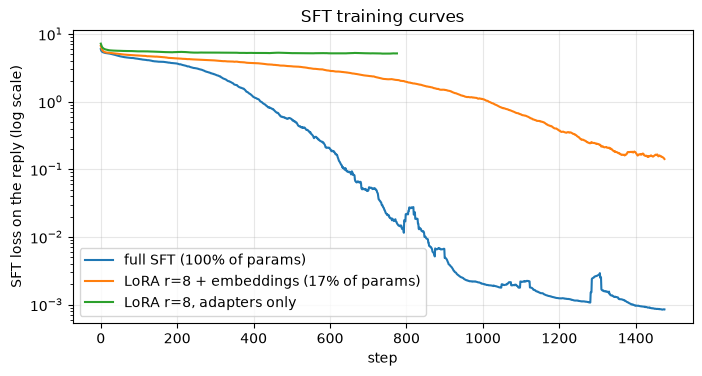

In [8]:
import matplotlib.pyplot as plt
def smooth(v, k=25):
    v = np.asarray(v, dtype=float); return np.convolve(v, np.ones(k) / k, mode="valid")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(smooth(losses_full), label="full SFT (100% of params)")
ax.plot(smooth(losses_lora), label=f"LoRA r=8 + embeddings ({100*n_train/n_total:.0f}% of params)")
ax.plot(smooth(losses_naive), label="LoRA r=8, adapters only")
ax.set_yscale("log"); ax.set_xlabel("step"); ax.set_ylabel("SFT loss on the reply (log scale)")
ax.set_title("SFT training curves"); ax.grid(alpha=.3); ax.legend(); plt.show()

### Rank ablation
How much rank do you need? Sweep `r` (with trainable embeddings) and watch quality vs trainable parameters. In the LoRA paper, r=4–8 already matches full fine-tuning on many tasks; on a task that needs *new* behaviour the rank matters more.

r= 1: adapter params   8,992  exact match   1.3%


r= 4: adapter params  35,968  exact match   1.3%


r=16: adapter params 143,872  exact match  48.0%


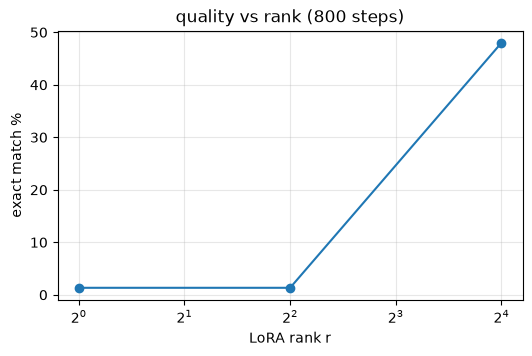

In [9]:
rs, ems, ns = [1, 4, 16], [], []
for r in rs:
    seed_everything(0)
    m = apply_lora(copy.deepcopy(base), r=r, alpha=2 * r, train_embeddings=True)
    train_sft(m, sft_train, fmt, steps=800, batch_size=32, lr=2e-3, device=device, log_every=0, params=trainable_parameters(m))
    em = exact_match_rate(lambda uu: greedy_answer(m, fmt, [10], uu, device=device), CASES)
    ems.append(em); ns.append(sum(p.numel() for p in lora_parameters(m)))
    print(f"r={r:2d}: adapter params {ns[-1]:>7,}  exact match {100*em:5.1f}%")
fig, ax = plt.subplots(figsize=(6, 3.5)); ax.plot(rs, [100*e for e in ems], "o-"); ax.set_xscale("log", base=2)
ax.set_xlabel("LoRA rank r"); ax.set_ylabel("exact match %"); ax.set_title("quality vs rank (800 steps)"); ax.grid(alpha=.3); plt.show()

## 4. Knowledge distillation

Transfer from a strong **teacher** (our full-SFT model) to a much smaller **student** (6× fewer parameters). Two flavours:

- **(a) Sequence-level / synthetic-data distillation** — the teacher *writes the answers* for prompts that have no labels, the student does SFT on them. This is how DeepSeek-R1-Distill and most small open models are made: labelled data is expensive, prompts are cheap.
- **(b) Logit distillation** — the student matches the teacher's full output distribution with temperature τ:
  $$\mathcal{L} = (1-\lambda)\,\text{CE}(y, p_s) + \lambda\,\tau^2\,\text{KL}(p_t^{\tau} \| p_s^{\tau})$$
  The soft targets carry "dark knowledge": the full probability of every token at every position, not just which one is correct — a much denser training signal than a hard label.

The realistic scenario: we only have **1,000 human-labelled** examples, but plenty of **unlabelled prompts**.

In [10]:
from llmsuite.finetune import train_distill
student_cfg = ModelConfig(vocab_size=V, d_model=64, n_layers=2, n_heads=4, n_kv_heads=2, max_seq_len=128)
seed_everything(0); student_init = TransformerLM(student_cfg)
print(f"teacher {human(sft_model.num_params())} -> student {human(student_init.num_params())}")

human_labelled = sft_train[:1000]                                   # the small labelled set we can afford
rng_p = random.Random(123)
unlabelled_prompts = [[rng_p.randint(1, 400) for _ in range(rng_p.randint(2, 5))] for _ in range(6000)]

t0 = time.time()                                                     # the teacher answers every prompt with greedy decoding
teacher_labelled = [fmt.build_example([10], u, greedy_answer(sft_model, fmt, [10], u, device=device)) for u in unlabelled_prompts]
print(f"teacher wrote {len(teacher_labelled):,} answers in {time.time() - t0:.0f}s")

# (1) Baseline: the student sees only the 1,000 human labels.
s_human = copy.deepcopy(student_init)
train_sft(s_human, human_labelled, fmt, steps=1500, lr=2e-3, device=device, log_every=0)
evaluate(s_human, "student: 1k human labels")

# (2) Sequence-level distillation: the human labels plus the answers the teacher wrote.
s_seq = copy.deepcopy(student_init)
train_sft(s_seq, human_labelled + teacher_labelled, fmt, steps=1500, lr=2e-3, device=device, log_every=0)
evaluate(s_seq, "student: + teacher answers")

# (3) Logit distillation on the same data, mixing the hard label with the teacher's soft distribution.
s_logit = copy.deepcopy(student_init)
train_distill(s_logit, sft_model, human_labelled + teacher_labelled, fmt, steps=1500, lr=2e-3, tau=2.0, lam=0.5, device=device, log_every=0)
evaluate(s_logit, "student: + logit distill")

teacher 758.91K -> student 125.25K


teacher wrote 6,000 answers in 134s


student: 1k human labels exact match  24.7%   reply perplexity    53.46


student: + teacher answers exact match  98.0%   reply perplexity     1.05


student: + logit distill exact match  44.7%   reply perplexity     2.39


(0.44666666666666666, 2.393798080415429)

**What happened.** With only the 1,000 human labels the small student barely learns the task. Adding the teacher's answers to 6,000 unlabelled prompts multiplies its training data for free and transforms the result. Logit distillation (matching the teacher's full distribution with τ = 2, λ = 0.5) is the more fragile of the two: across our runs on different hardware it landed both above and below sequence-level distillation, because its benefit depends on tuning τ, λ and the learning rate. That robustness gap is one reason why sequence-level distillation (the teacher writes data, the student does plain SFT) is the default way small LLMs are distilled today. Two caveats you should always keep in mind: the student inherits the teacher's mistakes (a distilled model is bounded by its teacher), and logit distillation needs access to the teacher's logits and the **same tokenizer** — with an API-only teacher you can only do sequence-level distillation.

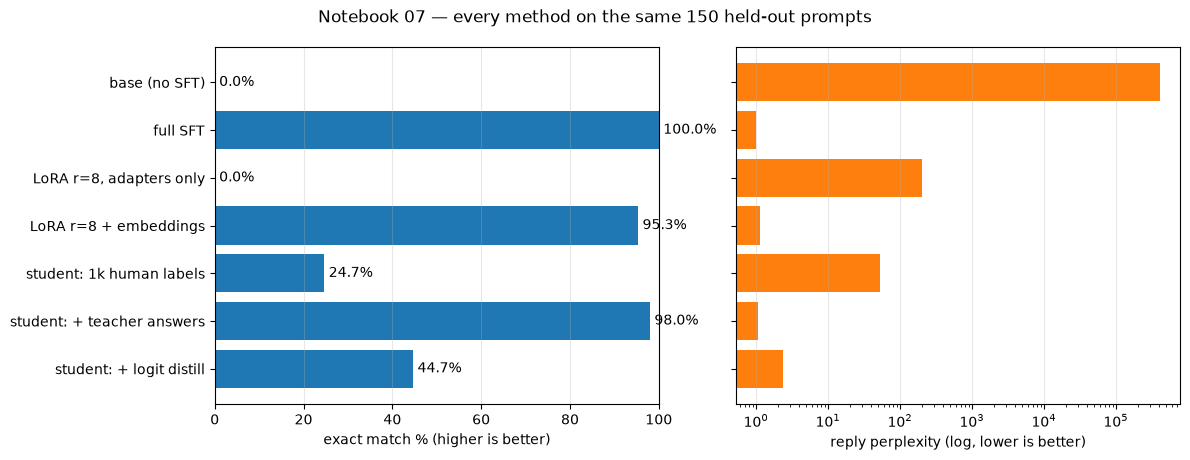

In [11]:
plot_results("Notebook 07 — every method on the same 150 held-out prompts")

## 5. Evaluation summary and what to measure in practice

| metric | what it tells you |
|---|---|
| exact match / task accuracy | did it learn the task? (your own eval set — build it *before* fine-tuning) |
| reply perplexity | calibration on held-out replies; compare checkpoints with the same tokenizer |
| general benchmarks before/after (MMLU, IFEval…) | did we break general abilities? (catastrophic forgetting) |
| LLM-judge on open-ended prompts | tone/helpfulness regressions |

Real-world equivalents: `trl.SFTTrainer(assistant_only_loss=True, packing=True)`, `peft.LoraConfig(target_modules="all-linear")`, `lm-eval-harness` for before/after benchmarks.

**Next:** `08_preference_rl_dpo_grpo.ipynb`.